# Interconnector outages: unmet demand per scenario

For every hour of the year: **how many % of the region's demand is not met** (load shedding),
one curve per disruption scenario. Electricity and heat are separate figures.

- **unmet % = load shedding ÷ demand**, per hour.
- **Demand** = everything used in the region except exports and storage charging.
  - Electricity: fixed demand + power-to-heat + EV charging + H2 + grid losses (same "demand" as in `base_network_dispatch.ipynb`).
  - Heat: the heat demand of all heat buses (urban central, decentral, rural incl. household buses).
- Shed electricity can still run heat pumps, so electricity shedding can also be "heat that was kept".

**Configure** in the next cell: `SCENARIOS` lists every scenario (name → solved network),
`PLOT` picks which of them to draw. Each scenario keeps its colour (by its position in
`SCENARIOS`) no matter which ones are plotted. Networks are loaded once and cached, so
changing `PLOT` and re-running the plot cells is fast.

Helpers (regional balance, grouping) come from `outage_helpers.py`.

In [7]:
from pathlib import Path

import pandas as pd
import pypsa
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

from outage_helpers import KIND_TITLE, region_balance, missing_demand, save

# ---- inputs ---------------------------------------------------------------
#REGION = "DK0 0AC"        # DK2 (Zealand) = "DK0 0AC"
#REGION_LABEL = "DK2"
REGION = "DK0 0AC"        # DK2 (Zealand) = "DK0 0AC"
REGION_LABEL = "DK2"
# every scenario: display name -> solved network. Order fixes the colours.
SCENARIOS = {
    "Base (no outage)": "results/base_network/network_solved.nc",
    "Øresund out": "results/disruptions/network_solved.nc",
    # "Øresund + Kontek out": "results/<run>/network_solved.nc",
    # "Great Belt out": "results/<run>/network_solved.nc",
    "Total disconnection": "results/disruptions_3/network_solved.nc",
}
# which of them to draw (any subset, in legend order)
PLOT = ["Base (no outage)", "Øresund out", "Total disconnection"]

RESAMPLE = None          # None = hourly curves; "D" = daily maximum of the hourly %
SHED_NOISE_MW = 0.1      # hourly shedding below this is solver noise and set to 0
FIG_DIR = Path("results/plots_outage")

# colour by position in SCENARIOS (Okabe-Ito, colour-blind safe); first = base, dark grey
SCENARIO_PALETTE = ["#4d4d4d", "#0072B2", "#E69F00", "#009E73", "#CC79A7", "#D55E00", "#56B4E9"]
SCENARIO_COLORS = {}     # optional fixed colours, e.g. {"Øresund out": "#0072B2"}

## Helpers

In [8]:
KINDS = ("power", "heat")
_CACHE = {}   # (path, region, noise) -> {kind: missing_demand DataFrame}


def scenario_result(path):
    # Load a network once, keep only the hourly unmet-demand series (the network is dropped).
    key = (str(Path(path).resolve()), REGION, SHED_NOISE_MW)
    if key not in _CACHE:
        print(f"loading {path} ...")
        n = pypsa.Network(path)
        _CACHE[key] = {k: missing_demand(region_balance(n, REGION, k, SHED_NOISE_MW)) for k in KINDS}
        del n
    return _CACHE[key]


def scenario_color(name):
    if name in SCENARIO_COLORS:
        return SCENARIO_COLORS[name]
    i = list(SCENARIOS).index(name)
    if i >= len(SCENARIO_PALETTE):
        raise ValueError(f"more than {len(SCENARIO_PALETTE)} scenarios: give '{name}' a colour in SCENARIO_COLORS")
    return SCENARIO_PALETTE[i]


def summary(results, kind):
    # One row per scenario: unserved energy, hours with shedding, peak and annual share.
    rows = {}
    for name, res in results.items():
        md = res[kind]
        shed = md.shed_MW
        rows[name] = {
            "unserved GWh": shed.sum() / 1e3,
            "hours with shedding": int((shed > 0).sum()),
            "peak shedding MW": shed.max(),
            "peak unmet %": md.missing_pct.max(),
            "unmet % of annual demand": shed.sum() / md.demand_MW.sum() * 100,
            "annual demand TWh": md.demand_MW.sum() / 1e6,
        }
    return pd.DataFrame(rows).T


def plot_missing(results, kind, resample=RESAMPLE):
    # One curve per scenario: % of the hourly demand that is not met.
    fig, ax = plt.subplots(figsize=(14, 4.8), constrained_layout=True)
    stats = summary(results, kind)
    ymax = 0.0
    for name, res in results.items():
        pct = res[kind].missing_pct
        if resample:
            pct = pct.resample(resample).max()
        s = stats.loc[name]
        if s["hours with shedding"]:
            label = (f"{name}: {s['unserved GWh']:,.1f} GWh unmet "
                     f"({s['unmet % of annual demand']:.2f} % of annual demand), "
                     f"{s['hours with shedding']:.0f} h, peak {s['peak unmet %']:.1f} %")
        else:
            label = f"{name}: no load shedding"
        ax.plot(pct.index, pct.values, drawstyle="steps-post", lw=1.2,
                color=scenario_color(name), label=label)
        ymax = max(ymax, pct.max())

    first = next(iter(results.values()))[kind].index
    ax.set_xlim(first[0], first[-1])
    ax.set_ylim(0, max(ymax * 1.08, 1.0))
    loc = mdates.MonthLocator()
    ax.xaxis.set_major_locator(loc)
    ax.xaxis.set_major_formatter(mdates.ConciseDateFormatter(loc))
    ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda y, _: f"{y:g} %"))
    ax.set_ylabel("unmet demand (% of hourly demand)" if not resample
                  else f"unmet demand ({resample} max of hourly %)")
    ax.grid(axis="y", color="#e0e0e0", lw=0.6)
    ax.set_axisbelow(True)
    for sp in ("top", "right"):
        ax.spines[sp].set_visible(False)
    ax.set_title(f"{REGION_LABEL}: unmet {KIND_TITLE[kind].lower()} demand per "
                 f"{'hour' if not resample else 'day (max hour)'}, "
                 f"{first[0]:%b %Y} – {first[-1]:%b %Y}",
                 loc="left", fontsize=12, fontweight="bold")
    ax.legend(loc="upper left", bbox_to_anchor=(0.0, -0.08), ncol=1, frameon=False, fontsize=9)
    return fig

## Load scenarios

Only the scenarios in `PLOT` are loaded; already loaded ones come from the cache.

In [9]:
unknown = [s for s in PLOT if s not in SCENARIOS]
if unknown:
    raise KeyError(f"not in SCENARIOS: {unknown}")
results = {name: scenario_result(SCENARIOS[name]) for name in PLOT}

# sanity check: unmet % never above 100
for name, res in results.items():
    for k in KINDS:
        assert res[k].missing_pct.max() <= 100 + 1e-6, (name, k)
print("loaded:", list(results))

loading results/base_network/network_solved.nc ...


INFO:pypsa.network.io:New version 1.4.0 available! (Current: 1.2.3)
INFO:pypsa.network.io:Imported network 'Unnamed Network' has buses, carriers, generators, global_constraints, lines, links, loads, storage_units, stores, sub_networks


[power] carriers in 'Other': ['methanolisation']
[heat] carriers in 'Other': ['Fischer-Tropsch', 'H2 Electrolysis', 'Sabatier', 'methanolisation', 'urban central solar thermal', 'urban central waste boiler']
loading results/disruptions/network_solved.nc ...


INFO:pypsa.network.io:New version 1.4.0 available! (Current: 1.2.3)
INFO:pypsa.network.io:Imported network 'Unnamed Network' has buses, carriers, generators, global_constraints, lines, links, loads, storage_units, stores, sub_networks


[power] carriers in 'Other': ['methanolisation']
[heat] carriers in 'Other': ['Fischer-Tropsch', 'H2 Electrolysis', 'Sabatier', 'methanolisation', 'urban central solar thermal', 'urban central waste boiler']
loading results/disruptions_3/network_solved.nc ...


INFO:pypsa.network.io:New version 1.4.0 available! (Current: 1.2.3)
INFO:pypsa.network.io:Imported network 'Unnamed Network' has buses, carriers, generators, global_constraints, lines, links, loads, storage_units, stores, sub_networks


[power] carriers in 'Other': ['gas pipeline', 'methanolisation']
[heat] carriers in 'Other': ['Fischer-Tropsch', 'H2 Electrolysis', 'Sabatier', 'methanolisation', 'urban central solar thermal', 'urban central waste boiler']
loaded: ['Base (no outage)', 'Øresund out', 'Total disconnection']


## Unmet demand over the year

Hourly steps (or daily maximum with `RESAMPLE = "D"`). The legend gives per scenario: unmet energy, its share of the annual demand, hours with shedding and the worst hour.

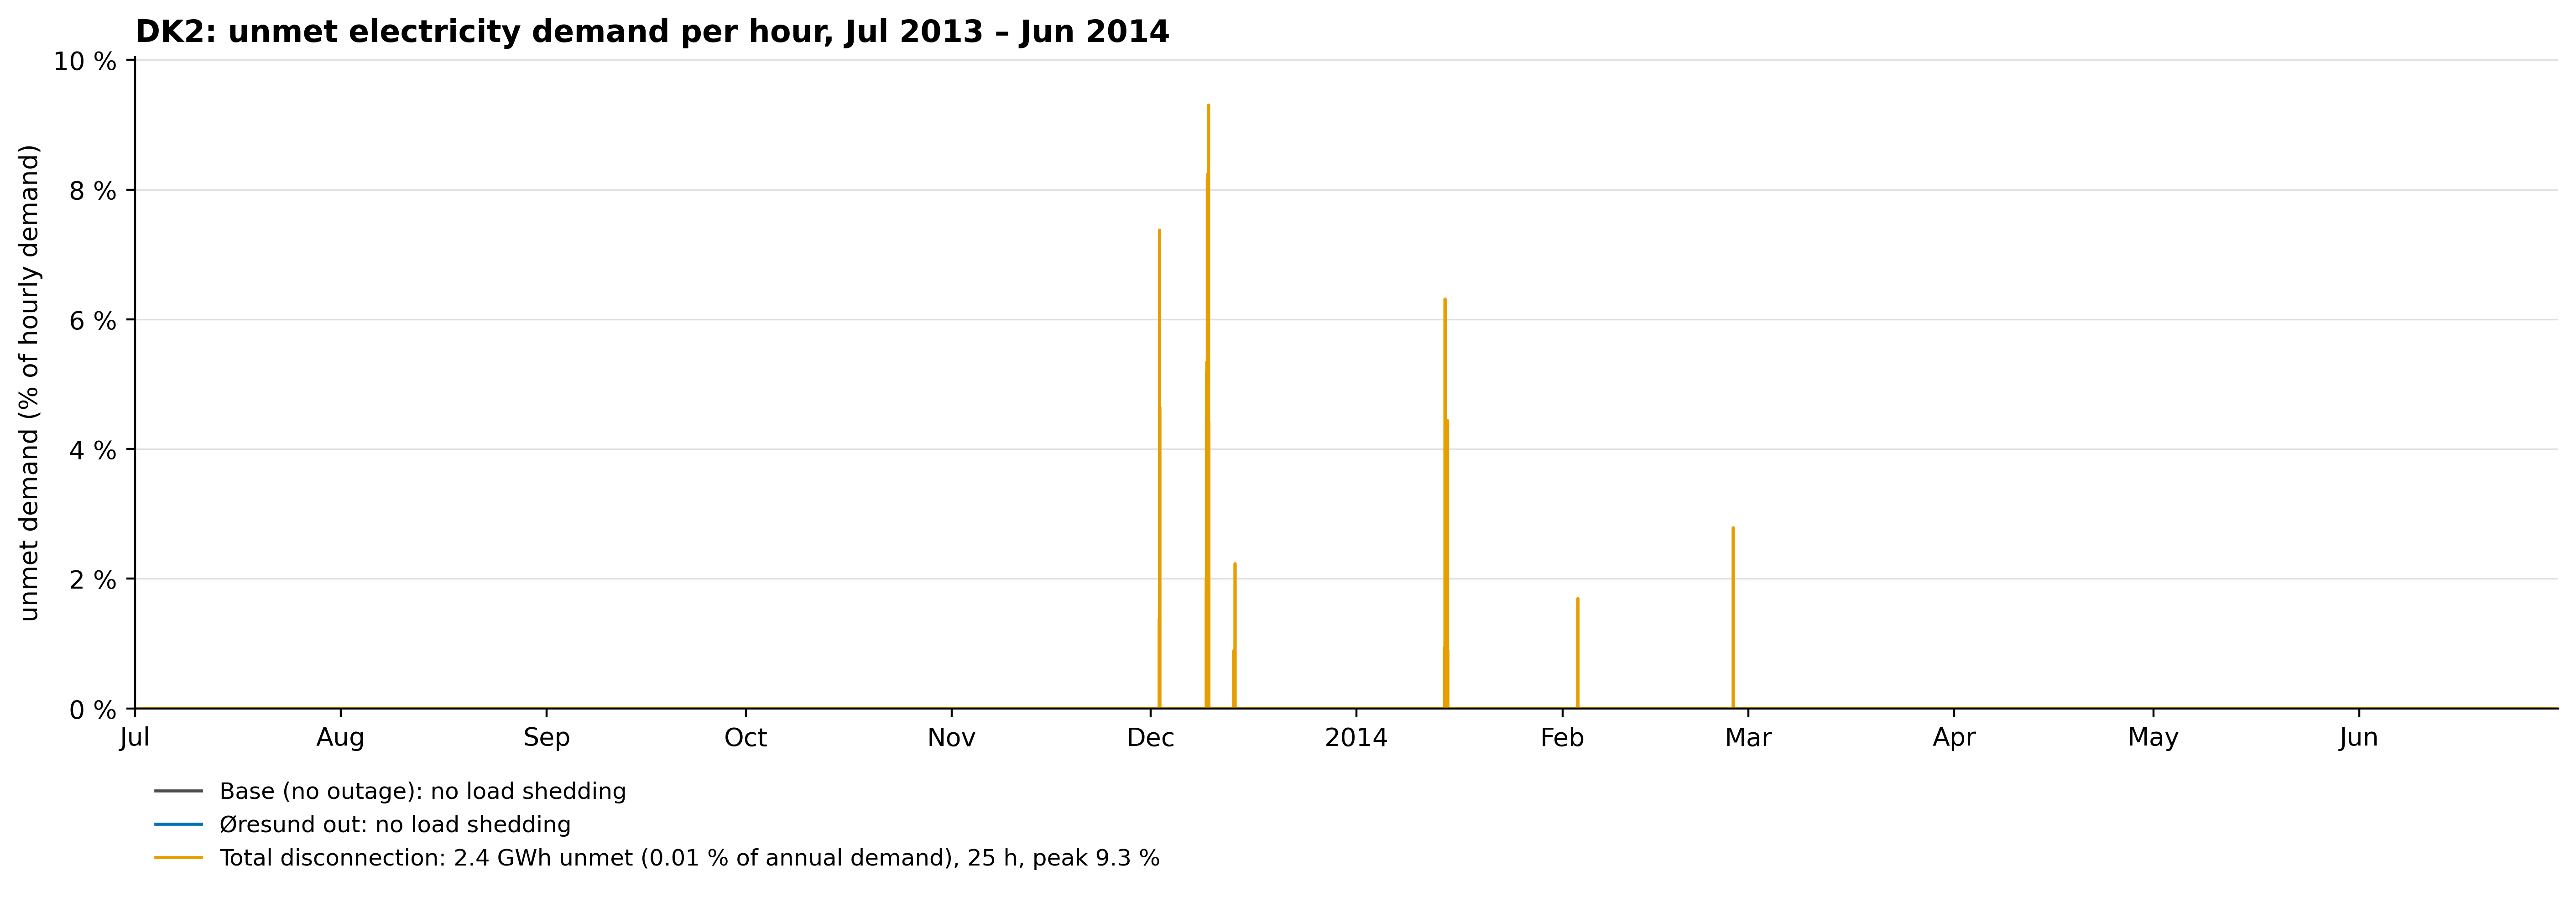

In [10]:
fig = plot_missing(results, "power")
save(fig, f"missing_demand_{REGION_LABEL}_power", FIG_DIR)
plt.show()

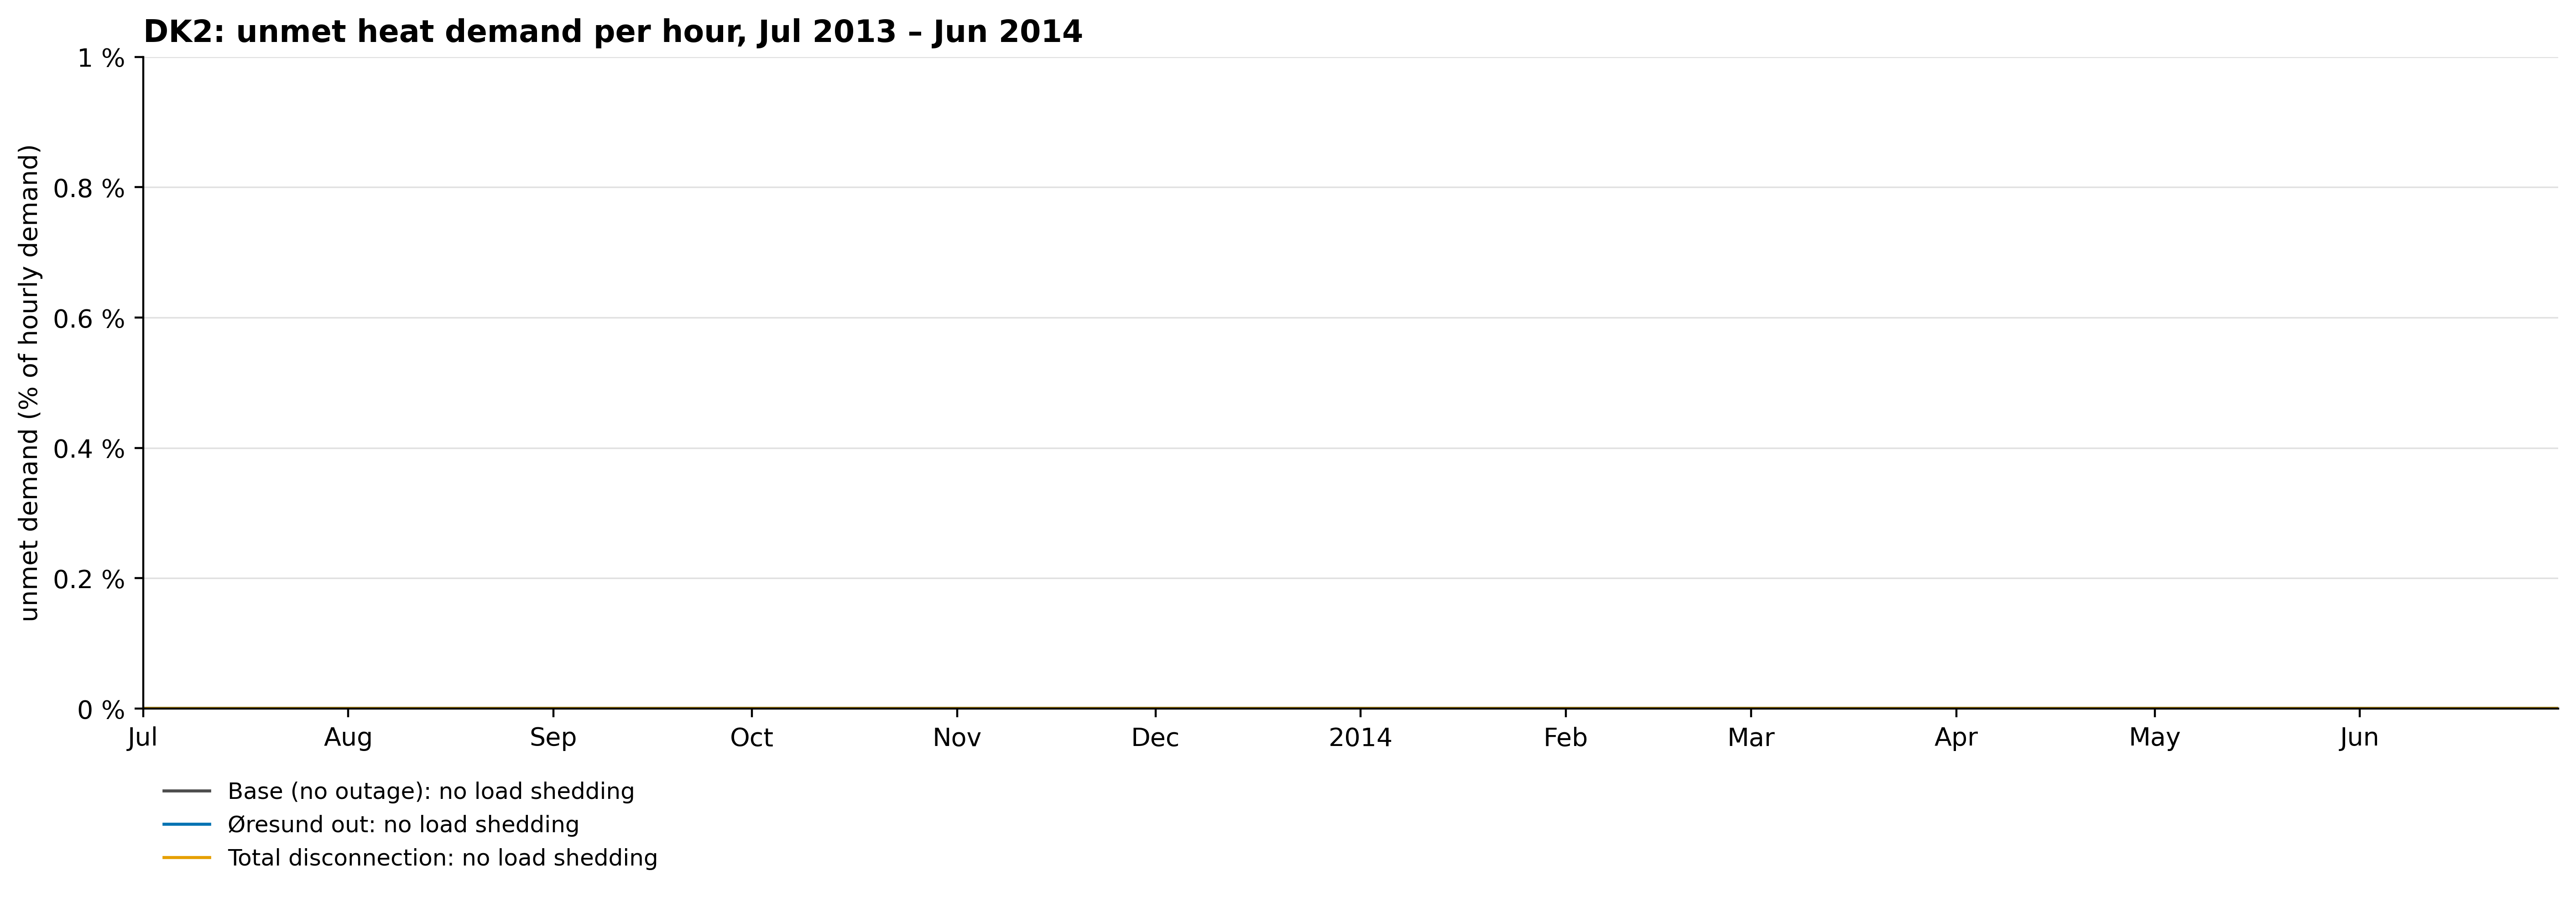

In [11]:
fig = plot_missing(results, "heat")
save(fig, f"missing_demand_{REGION_LABEL}_heat", FIG_DIR)
plt.show()

## Summary per scenario

In [12]:
pd.concat({KIND_TITLE[k]: summary(results, k) for k in KINDS}).round(2)

unserved GWh  hours with shedding  \
Electricity Base (no outage)             0.00                  0.0   
            Øresund out                  0.00                  0.0   
            Total disconnection          2.37                 25.0   
Heat        Base (no outage)             0.00                  0.0   
            Øresund out                  0.00                  0.0   
            Total disconnection          0.00                  0.0   

                                 peak shedding MW  peak unmet %  \
Electricity Base (no outage)                 0.00           0.0   
            Øresund out                      0.00           0.0   
            Total disconnection            233.35           9.3   
Heat        Base (no outage)                 0.00           0.0   
            Øresund out                      0.00           0.0   
            Total disconnection              0.00           0.0   

                                 unmet % of annual demand  annual demand TWh  
Electricity Base (no outage)                         0.00              17.27  
            Øresund out                              0.00              16.99  
            Total disconnection                      0.01              16.68  
Heat        Base (no outage)                         0.00              23.55  
            Øresund out                              0.00              23.55  
            Total disconnection                      0.00              23.55